# 1. Data Preprocessing and Exploration

## 1.1 Loading the data

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

day = pd.read_csv("day.csv")
day.head()




,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


I first use Pandas to load the comma-separated values dataset into Python and display the first 5 rows to make sure that the dataset is being loaded correctly.

In [4]:
day.shape

(731, 16)

The shape of the data is represented by (731, 16), which means there are 731 samples and 16 columns in the raw dataset.

In [5]:
day.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')

The elements are the names of the 16 columns in the raw dataset, including cnt, the target variable.

In [6]:
day.dtypes

,0
instant,int64
dteday,object
season,int64
yr,int64
mnth,int64
holiday,int64
weekday,int64
workingday,int64
weathersit,int64
temp,float64


The resulting table shows the data types of each column, which in this case are integers, floats, and objects. An observation I have made is that, unlike the other columns, the dteday column has an object data type.


## 1.2 Data cleaning and preprocessing

### Missing or malformed values

In [7]:
day.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


The output shows that there are no missing values in any of the columns, since the missing-value count is 0 for every column.

In [8]:
day.isin(["?", "unknown", "-", ""]).sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


The output shows that none of the checked placeholder values (?, unknown, -, or an empty string) are present in any of the columns.

In [9]:
pd.to_datetime(day["dteday"], errors="coerce").isna().sum()

np.int64(0)

The result is 0, meaning that all values in the dteday column can be interpreted as valid dates and there are no malformed date values.

In [10]:
day.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


The output shows that the numerical values fall within reasonable ranges, with no obvious malformed or extreme placeholder values. However, describe() summarizes columns based on their numeric data type and does not check if integer-coded categorical variables contain only valid category values, so these variables must be checked separately.

In [11]:
day["season"].unique()

array([1, 2, 3, 4])

In [12]:
day["yr"].unique()

array([0, 1])

In [13]:
day["mnth"].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12])

In [14]:
day["holiday"].unique()

array([0, 1])

In [15]:
day["weekday"].unique()

array([6, 0, 1, 2, 3, 4, 5])

In [16]:
day["workingday"].unique()

array([0, 1])

In [17]:
day["weathersit"].unique()

array([2, 1, 3])

The unique values of the categorical and discrete variables all fall within their expected ranges, with no unexpected category codes present. This indicates that there are no obvious malformed values in these columns. Since no missing values or malformed placeholder values were found, no rows need to be removed and no imputation is necessary.

### Irrelevant or identifier features

In [18]:
day_clean = day.copy()
day_clean = day_clean.drop(columns ="instant")
day_clean.columns

Index(['dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday',
       'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual',
       'registered', 'cnt'],
      dtype='object')

I have removed the column instant as it simply identifies the order in which the instances were recorded and therefore does not represent a meaningful predictive feature.

In [19]:
day_clean = day_clean.drop(columns=["workingday"])
day_clean.columns

Index(['dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'weathersit',
       'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt'],
      dtype='object')

I removed workingday because it is fully determined by weekday and holiday, making it redundant with the other predictor variables.

In [20]:
day["dteday"].nunique()

731

The dteday column has 731 unique values, which is equal to the number of samples in the dataset, meaning that each observation has a unique date.

In [21]:
day_clean = day_clean.drop(columns ="dteday")
day_clean.columns

Index(['season', 'yr', 'mnth', 'holiday', 'weekday', 'weathersit', 'temp',
       'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt'],
      dtype='object')

I have removed the dteday column because each sample has a unique date and the useful date-related information is already represented by variables such as yr, mnth, weekday, and season. In addition, dteday is stored as an object and cannot be used directly as a numerical input for linear regression. The remaining columns represent characteristics of the day rather than identifiers, so I do not remove any additional features at this stage.

In [22]:
(day["casual"] + day["registered"] == day["cnt"]).all()

np.True_

The result is True, meaning that casual and registered sum to the target variable cnt for every sample. Therefore, using these columns as predictors would cause data leakage because they directly reveal the target.

In [23]:
day_clean = day_clean.drop(columns = ["casual", "registered"])
day_clean.columns

Index(['season', 'yr', 'mnth', 'holiday', 'weekday', 'weathersit', 'temp',
       'atemp', 'hum', 'windspeed', 'cnt'],
      dtype='object')

Due to this data leakage, I remove casual and registered from the predictor variables.

### Categorical (discrete) features

In [24]:
day_clean = pd.get_dummies(day_clean, columns=["season", "mnth", "weekday", "weathersit"], drop_first=True, dtype=int)
day_clean.columns

Index(['yr', 'holiday', 'temp', 'atemp', 'hum', 'windspeed', 'cnt', 'season_2',
       'season_3', 'season_4', 'mnth_2', 'mnth_3', 'mnth_4', 'mnth_5',
       'mnth_6', 'mnth_7', 'mnth_8', 'mnth_9', 'mnth_10', 'mnth_11', 'mnth_12',
       'weekday_1', 'weekday_2', 'weekday_3', 'weekday_4', 'weekday_5',
       'weekday_6', 'weathersit_2', 'weathersit_3'],
      dtype='object')

I have one-hot encoded the season, mnth, and weekday columns because the numbers in these columns represent categories rather than numerical values. I also used drop_first=True to remove one dummy column from each categorical feature, since keeping all of them would create redundant information when the bias term is included. The output confirms that the original columns have been replaced by dummy variables, with the first category of each variable being used as the reference category. I keep yr and holiday unchanged because they are already binary variables. I also one-hot encode weathersit because, although its categories have an ordering from less severe to more severe weather, treating the category codes as numerical values would assume equal changes between each weather level.

### Feature scaling and normalization

I considered applying additional scaling or normalization as suggested in the assignment. However, the continuous variables temp, atemp, hum, and windspeed are already approximately between 0 and 1, while the binary and one-hot encoded variables are represented using 0 and 1. Therefore, I decided that additional scaling would be unnecessary for this dataset.

### Duplicates

In [25]:
day_clean.duplicated().sum()

np.int64(0)

This verifies that there are no duplicate rows in the cleaned dataset.

## 1.3 Data visualization and exploratory analysis

The data are visualized to better understand the distributions and relationships between the features and the target variable. Histograms are used to examine feature ranges, skewness, and possible unusual values, while scatter plots are used to examine relationships with the target and identify possible non-linear patterns. Bar plots are used for categorical variables to compare average rental demand across categories.

### Distribution of the target variable

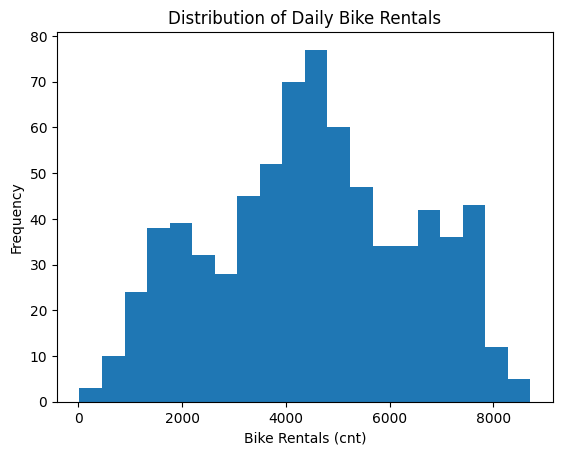

In [26]:
plt.hist(day["cnt"], bins=20)
plt.xlabel("Bike Rentals (cnt)")
plt.ylabel("Frequency")
plt.title("Distribution of Daily Bike Rentals")
plt.show()

The histogram shows that the cnt values range from approximately 0 to 8,700 daily bike rentals. Most of the values appear to be concentrated between approximately 1,000 and 8,000 rentals per day. The distribution does not appear to be strongly skewed, although there are several peaks in the data. There do not appear to be any obvious extreme outliers from this histogram.

### Distribution of continuous features

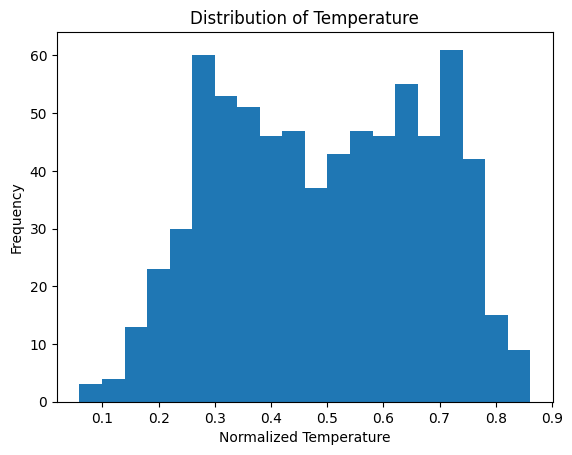

In [27]:
plt.hist(day["temp"], bins=20)
plt.xlabel("Normalized Temperature")
plt.ylabel("Frequency")
plt.title("Distribution of Temperature")
plt.show()

The histogram shows that the normalized temperature values range from approximately 0.06 to 0.86, with most values falling between approximately 0.2 and 0.75. The distribution does not appear to be strongly skewed, although there are multiple peaks in the data. There are also fewer observations at the lowest and highest temperatures, with no obvious extreme outliers.

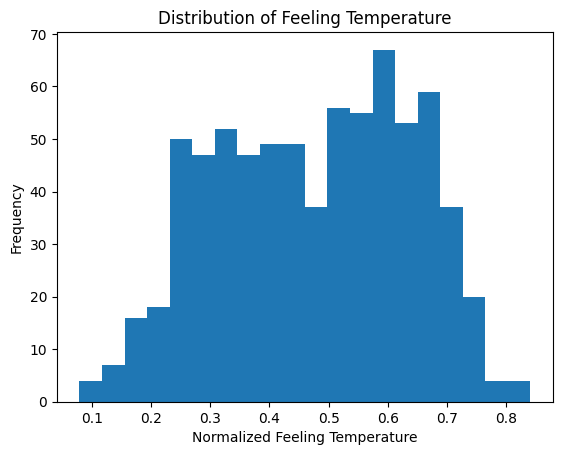

In [28]:
plt.hist(day["atemp"], bins=20)
plt.xlabel("Normalized Feeling Temperature")
plt.ylabel("Frequency")
plt.title("Distribution of Feeling Temperature")
plt.show()

The histogram shows that the normalized feeling temperature ranges from approximately 0.08 to 0.84, with most values falling between approximately 0.2 and 0.72. The distribution does not appear to be strongly skewed and contains multiple peaks. There are fewer observations at the lowest and highest values, and no obvious extreme outliers are visible.

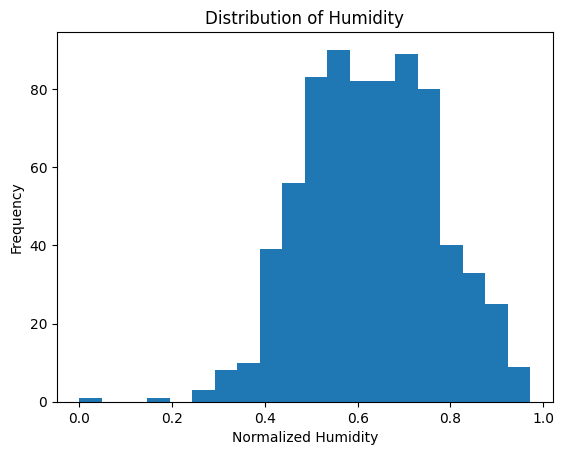

In [29]:
plt.hist(day["hum"], bins=20)
plt.xlabel("Normalized Humidity")
plt.ylabel("Frequency")
plt.title("Distribution of Humidity")
plt.show()

The normalized humidity values range from approximately 0 to 0.97, with most observations between approximately 0.4 and 0.9. The main distribution does not appear strongly skewed, but there are a small number of unusually low humidity values. In particular, the observations near 0 and 0.2 may represent potential outliers.

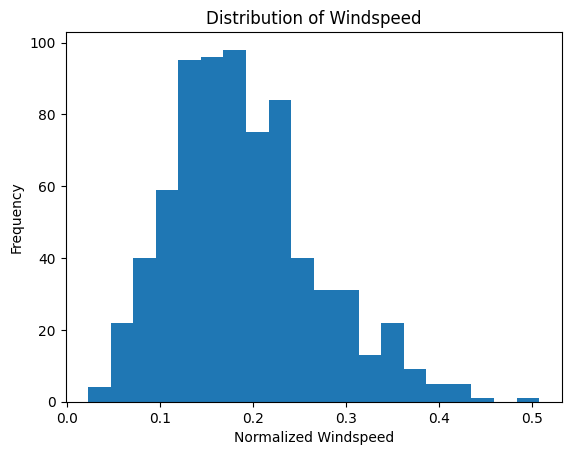

In [30]:
plt.hist(day["windspeed"], bins=20)
plt.xlabel("Normalized Windspeed")
plt.ylabel("Frequency")
plt.title("Distribution of Windspeed")
plt.show()

The normalized windspeed values range from approximately 0.02 to 0.51, with most observations concentrated between roughly 0.10 and 0.25. The distribution is right-skewed because the frequency gradually decreases as windspeed increases, creating a longer tail toward the higher values. There may also be a potential high outlier near 0.50.

### Relationships between continuous features and the target

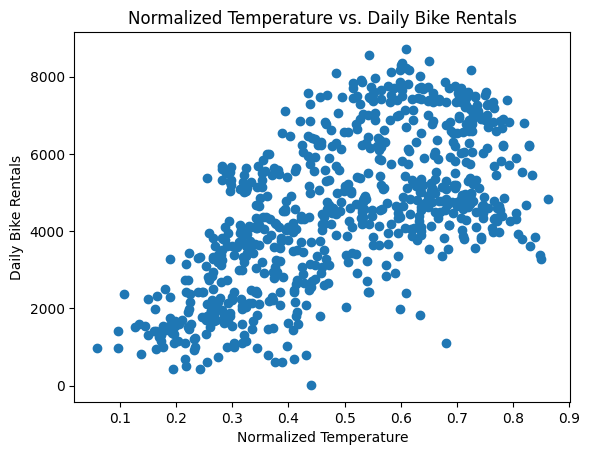

In [31]:
plt.scatter(day["temp"], day["cnt"])
plt.xlabel("Normalized Temperature")
plt.ylabel("Daily Bike Rentals")
plt.title("Normalized Temperature vs. Daily Bike Rentals")
plt.show()

The scatter plot shows an overall positive relationship between normalized temperature and daily bike rentals, since rental counts generally increase as temperature rises. However, the relationship does not appear to be perfectly linear because rental counts seem to level off or decrease at the highest temperatures. There is also considerable variation in rental counts for similar temperatures, suggesting that other features also affect bike rentals.

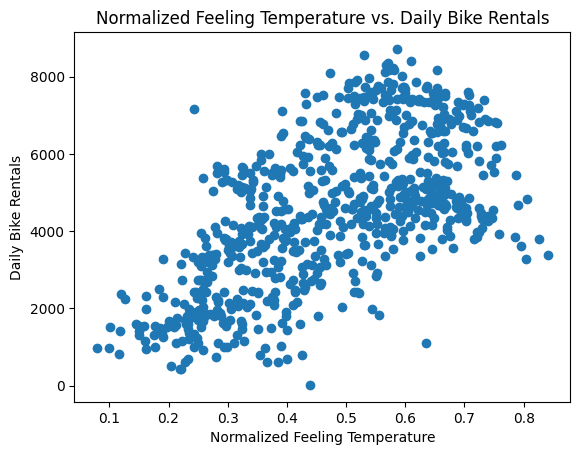

In [32]:
plt.scatter(day["atemp"], day["cnt"])
plt.xlabel("Normalized Feeling Temperature")
plt.ylabel("Daily Bike Rentals")
plt.title("Normalized Feeling Temperature vs. Daily Bike Rentals")
plt.show()

The scatter plot shows an overall positive relationship between normalized feeling temperature and daily bike rentals. However, the relationship does not appear completely linear because rentals seem to level off or decrease at higher temperatures. There are also a few observations that lie noticeably away from the main pattern, which may represent potential outliers.

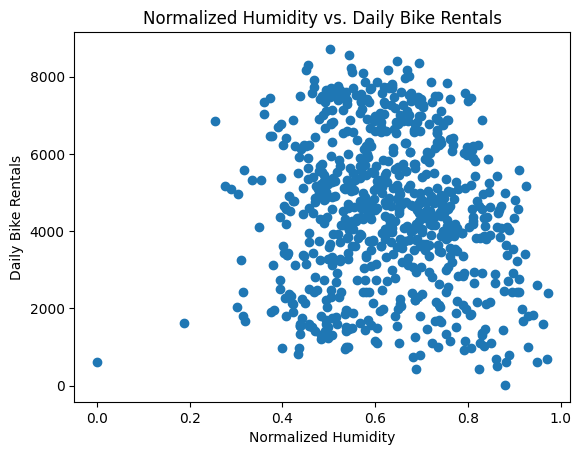

In [33]:
plt.scatter(day["hum"], day["cnt"])
plt.xlabel("Normalized Humidity")
plt.ylabel("Daily Bike Rentals")
plt.title("Normalized Humidity vs. Daily Bike Rentals")
plt.show()

The scatter plot does not show a strong linear relationship between normalized humidity and daily bike rentals, since the points are widely scattered across the plot. There are also a few unusual observations, particularly at very low humidity values, which may represent potential outliers.

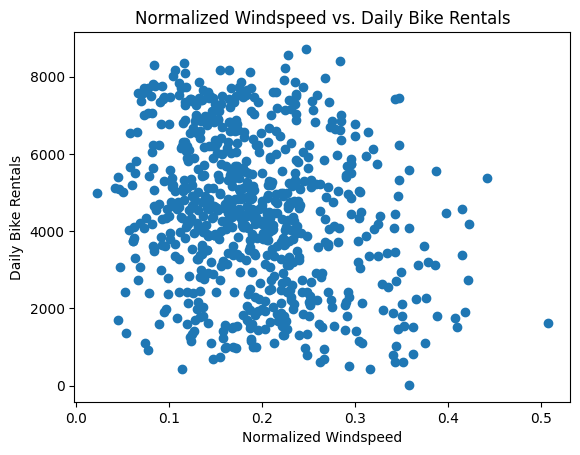

In [34]:
plt.scatter(day["windspeed"], day["cnt"])
plt.xlabel("Normalized Windspeed")
plt.ylabel("Daily Bike Rentals")
plt.title("Normalized Windspeed vs. Daily Bike Rentals")
plt.show()

The scatter plot does not show a strong linear relationship between normalized windspeed and daily bike rentals because there is large variation in rental counts for similar windspeed values. There may be a weak tendency for rentals to decrease at higher windspeed values, but the pattern is not very clear. The observation near a normalized windspeed of 0.5 may also represent a potential outlier.

### Potential outliers

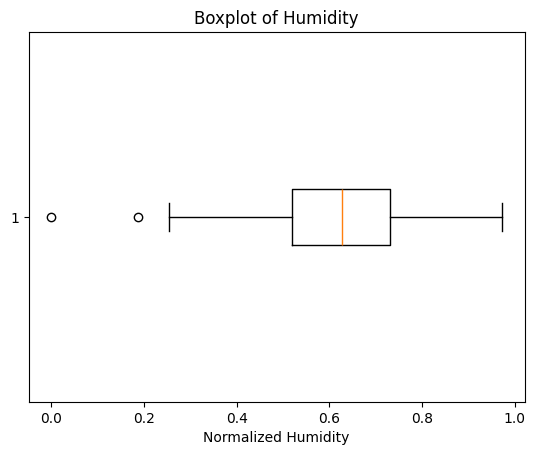

In [35]:
plt.boxplot(day["hum"], vert=False)
plt.xlabel("Normalized Humidity")
plt.title("Boxplot of Humidity")
plt.show()

The boxplot shows that the middle 50% of normalized humidity values lie between approximately 0.52 and 0.73, with a median around 0.63. Two unusually low humidity values appear below the lower whisker, indicating potential outliers. No similarly extreme high-humidity values are visible.

Based on this analysis, I decided not to remove the potential outliers because there is no evidence that they are incorrect values, and unusual weather conditions can still be valid observations. I also leave the windspeed values unchanged despite the right-skewed distribution, since linear regression does not require the predictor variables themselves to be normally distributed.

### Relationships between categorical features and the target

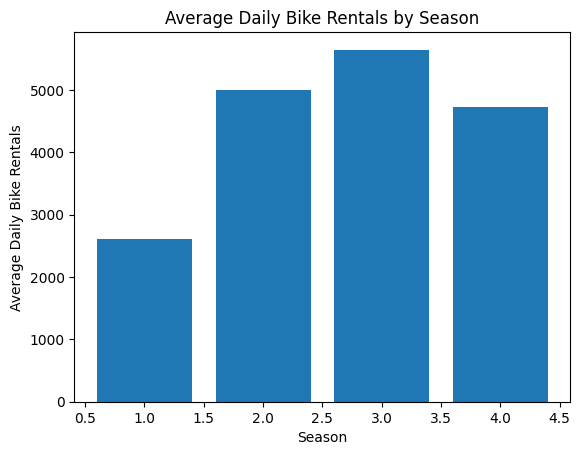

In [36]:
average_rentals = day.groupby("season")["cnt"].mean()

plt.bar(average_rentals.index, average_rentals.values)
plt.xlabel("Season")
plt.ylabel("Average Daily Bike Rentals")
plt.title("Average Daily Bike Rentals by Season")
plt.show()

Average daily bike rentals differ substantially across seasons. Season 1 has the lowest average rental count, while Season 3 has the highest. Seasons 2 and 4 also have considerably higher average rentals than Season 1, suggesting that season is associated with bike rental demand.

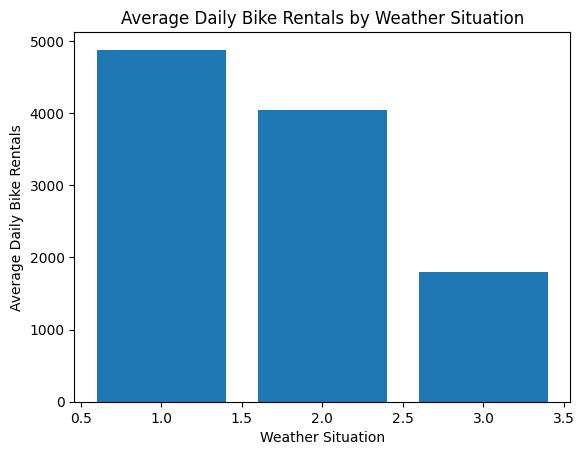

In [37]:
average_rentals_weather = day.groupby("weathersit")["cnt"].mean()

plt.bar(average_rentals_weather.index, average_rentals_weather.values)
plt.xlabel("Weather Situation")
plt.ylabel("Average Daily Bike Rentals")
plt.title("Average Daily Bike Rentals by Weather Situation")
plt.show()

Average daily bike rentals decrease substantially as the weather situation becomes less favorable. Weather category 1 has the highest average rental count, while category 3 has the lowest by a large margin. This suggests that weather conditions are strongly associated with bike rental demand.

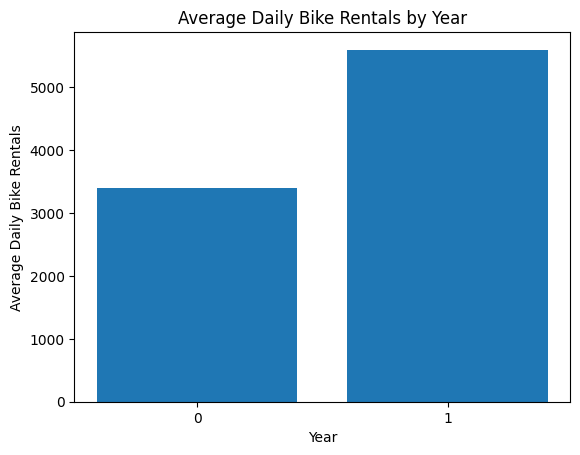

In [38]:
average_rentals_year = day.groupby("yr")["cnt"].mean()

plt.bar(average_rentals_year.index, average_rentals_year.values)
plt.xlabel("Year")
plt.ylabel("Average Daily Bike Rentals")
plt.title("Average Daily Bike Rentals by Year")
plt.xticks([0, 1])
plt.show()

Average daily bike rentals are substantially higher for year 1 than for year 0. This indicates that bike rental demand increased considerably between the two years in the dataset, suggesting that year is an important predictor of rental counts.

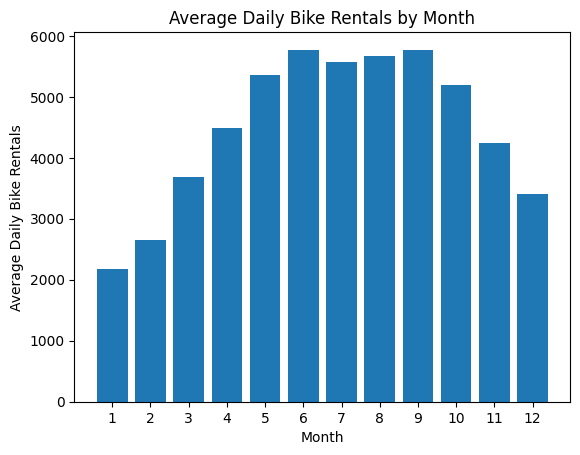

In [39]:
average_rentals_month = day.groupby("mnth")["cnt"].mean()

plt.bar(average_rentals_month.index, average_rentals_month.values)
plt.xlabel("Month")
plt.ylabel("Average Daily Bike Rentals")
plt.title("Average Daily Bike Rentals by Month")
plt.xticks(range(1, 13))
plt.show()

Average daily bike rentals vary considerably throughout the year. Rentals generally increase from the winter months into spring and summer, remain relatively high through early fall, and then decrease toward the end of the year. This pattern suggests a strong seasonal relationship between month and bike rental demand. The rise and decline across the months also indicate that the relationship between month and rental demand is not simply linear.

# 2. Methods

## 2.1 Model implementation

In [40]:
class LinearRegression:

    def __init__(self):
        self.weights = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        X_design = np.column_stack((np.ones(X.shape[0]), X))

        A = X_design.T @ X_design
        b = X_design.T @ y

        self.weights = np.linalg.solve(A, b)

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)

        X_design = np.column_stack((np.ones(X.shape[0]), X))

        return X_design @ self.weights

The LinearRegression class implements linear regression using the analytical closed-form solution. The fit method first converts the data to NumPy arrays and adds a column of ones to include the bias term. It then constructs the normal equations X^TXw = X^Ty and solves them using np.linalg.solve rather than calculating a matrix inverse, which is more numerically stable. The learned coefficients are stored in self.weights. The predict method adds the same bias column to new data and computes predictions using Xw.

## 2.2 Train/test split

In [41]:
X = day_clean.drop(columns=["cnt"])
y = day_clean["cnt"]

rng = np.random.default_rng(42)
indices = rng.permutation(len(day_clean))

train_size = int(0.8 * len(day_clean))

train_indices = indices[:train_size]
test_indices = indices[train_size:]

X_train = X.iloc[train_indices]
X_test = X.iloc[test_indices]

y_train = y.iloc[train_indices]
y_test = y.iloc[test_indices]

I split the cleaned dataset into predictor variables X and the target variable y, where y is cnt. I then randomly shuffled the row indices using a fixed random seed so that the same split can be reproduced each time the notebook is run. I used 80% of the observations for the training set and the remaining 20% for the test set. The training set will be used to fit the linear regression model, while the test set will only be used for final evaluation so that the model is evaluated on data it has not seen during training.

In [42]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (584, 28)
X_test: (147, 28)
y_train: (584,)
y_test: (147,)


The output confirms that the dataset was split into 584 training observations and 147 test observations, corresponding to approximately an 80/20 split. Both the training and test feature matrices contain the same 28 predictor variables, and the number of target values matches the number of observations in each set.

In [43]:
model = LinearRegression()
model.fit(X_train, y_train);

I create an instance of the LinearRegression class and fit it using only the training data. During fitting, the model learns the regression coefficients from X_train and y_train, while the test set remains unused until final evaluation.

# 3. Results

## 3.1 Evaluation metric

In [44]:
def mse(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    return np.mean((y_true - y_pred) ** 2)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

train_mse = mse(y_train, y_train_pred)
test_mse = mse(y_test, y_test_pred)

print("Training MSE:", train_mse)
print("Test MSE:", test_mse)

Training MSE: 564552.249746658
Test MSE: 620125.2833386887


MSE measures the average squared difference between the actual and predicted rental counts, so a lower MSE indicates smaller prediction errors.

The linear regression model obtains a training MSE of approximately 564,552 and a test MSE of approximately 620,125. The test MSE is higher than the training MSE, which is expected because the test set contains observations that were not used to fit the model. However, the two values are relatively similar, suggesting that the model generalizes reasonably consistently from the training data to the test data.

## 3.2 Results presentation and interpretation

In [45]:
results = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "MSE": [train_mse, test_mse]
})

results

,Dataset,MSE
0,Training,564552.249747
1,Test,620125.283339


The table summarizes the MSE for the training and test sets.

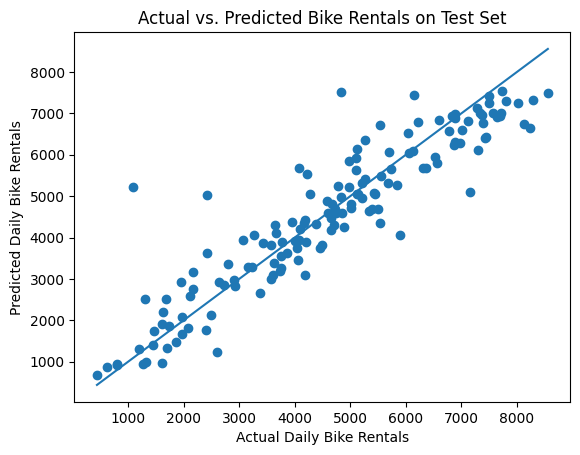

In [46]:
plt.scatter(y_test, y_test_pred)

minimum = min(y_test.min(), y_test_pred.min())
maximum = max(y_test.max(), y_test_pred.max())

plt.plot([minimum, maximum], [minimum, maximum])

plt.xlabel("Actual Daily Bike Rentals")
plt.ylabel("Predicted Daily Bike Rentals")
plt.title("Actual vs. Predicted Bike Rentals on Test Set")
plt.show()

The predicted values generally follow the diagonal line, which means that the model is usually predicting values fairly close to the actual number of bike rentals. However, there are still some points that are far from the line, showing that the model makes larger errors for some observations. The model also seems to predict some of the lower rental counts too high and some of the higher rental counts too low. Overall, the model captures the general pattern in the data, but it does not predict every observation equally well.

### Limitations and next steps

One limitation of this model is that linear regression assumes the relationships between the predictor variables and bike rentals are linear. However, from the exploratory analysis, some of the variables appeared to have non-linear relationships with rental demand. This could explain some of the larger errors in the actual vs. predicted plot. Another limitation is that the model was only evaluated using one random train/test split, so the test result could be different depending on which observations end up in each set. In the future, non-linear features could be added to better represent these relationships, and multiple train/test splits or cross-validation could be used to get a more reliable estimate of the model's performance.

# 4. Statement on the use of LLMs and other resources

I used LLMs to clarify how some of the functions worked, and check the correctness of my implementation and explanations. I used the feedback to revise my work, and a full log of my LLM interactions is provided separately.